In [83]:
import numpy as np
import matplotlib.pyplot as plt

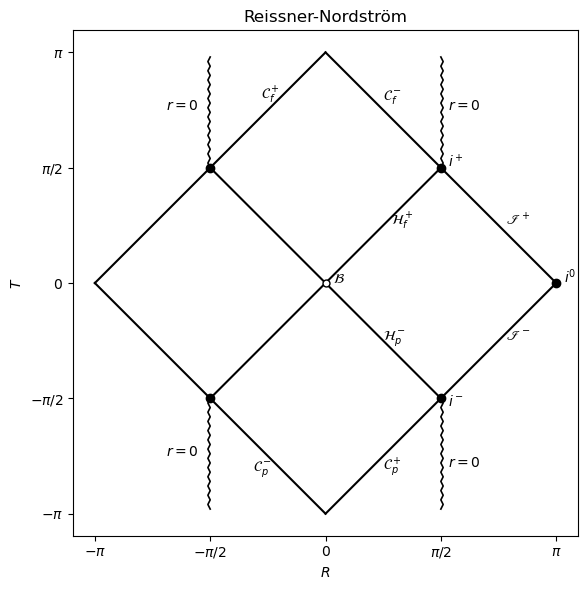

In [ ]:
class Reissner_diagram:
    def _diag_init(self):
        scale = 6
        plt.figure(figsize=(scale, scale))
        
        # Forcing same scale on both axes
        ax = plt.gca()
        ax.set_aspect('equal', adjustable='box')

        # set ticks to pi
        ticks = [-np.pi, -np.pi/2, 0, np.pi/2, np.pi]
        tick_labels = [r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$']

        ax.set_xticks(ticks)
        ax.set_yticks(ticks)
        ax.set_xticklabels(tick_labels)
        ax.set_yticklabels(tick_labels)



        # y = x line
        x_line = np.array([-np.pi/2, np.pi/2])
        y_line = x_line
        plt.plot(x_line, y_line, lw=1.5, color='black')
        plt.plot(x_line - np.pi/2, y_line + np.pi/2, lw=1.5, color='black')
        plt.plot(x_line + np.pi/2, y_line - np.pi/2, lw=1.5, color='black')


        # line y = -x
        y_line2 = -x_line
        plt.plot(x_line, y_line2, lw=1.5, color='black')
        plt.plot(x_line + np.pi/2, y_line2 + np.pi/2, lw=1.5, color='black')
        plt.plot(x_line - np.pi/2, y_line2 - np.pi/2, lw=1.5, color='black')


        # zigzags
        x_start = np.pi/2
        y_start = np.pi/2
        y_end = np.pi
        x_end = x_start

        n_zigzags = 25
        width = (y_end - y_start)/n_zigzags
        


        y = np.array([y_start + l*width for l in range(n_zigzags)])
        x = np.array([x_start + (i % 2) * width/2 for i in range(n_zigzags)])
        l_width = 1.2
        plt.plot(x, y, lw=l_width, color='black')
        plt.plot(-x, y, lw=l_width, color='black')
        plt.plot(x, -y, lw=l_width, color='black')
        plt.plot(-x, -y, lw=l_width, color='black')

        margin = 0.3
        plt.xlim(-np.pi - margin, np.pi + margin)
        plt.ylim(-np.pi - margin, np.pi + margin)
        plt.xlabel(r'$R$')
        plt.ylabel(r'$T$')
        plt.title(r'Reissner-Nordström')
        plt.tight_layout()

    def _diag_markers(self):
        
        # Dots for  i-, i0, i+
        plt.plot(np.pi/2, np.pi/2, marker='o', color='black')
        plt.plot(-np.pi/2, -np.pi/2, marker='o', color='black')

        plt.plot(np.pi/2, -np.pi/2, marker='o', color='black')
        plt.plot(-np.pi/2, np.pi/2, marker='o', color='black')
        
        plt.plot(np.pi, 0, marker='o', color='black')
        

        # Bifurcation sphere
        plt.plot(0, 0, marker='o', markerfacecolor='white', markeredgecolor='black', markersize=5, linestyle='None')

        # denoting i-, i0, i+
        plt.text(np.pi/2 + 0.1, -np.pi/2 - 0.1, r'$i^-$')
        plt.text(np.pi + 0.1, 0, r'$i^0$')
        plt.text(np.pi/2 + 0.1, np.pi/2, r'$i^+$')

        # denoting r = 0
        plt.text(np.pi/2 + 0.1, 3*np.pi/4, r'$r = 0$')
        plt.text(np.pi/2 + 0.1, -3*np.pi/4 - 0.15, r'$r = 0$')
        plt.text(-np.pi/2 - 0.6, 3*np.pi/4, r'$r = 0$')
        plt.text(-np.pi/2 - 0.6, -3*np.pi/4, r'$r = 0$')

        # denoting H+-
        plt.text(np.pi/4 + 0.1, np.pi/4, r'$\mathcal{H}^+_f$')
        plt.text(np.pi/4, -np.pi/4, r'$\mathcal{H}^-_p$')

        # denoting inner horizon
        plt.text( np.pi/4, 3*np.pi/4 + 0.14, r'$\mathcal{C}^-_f$')
        plt.text(-np.pi/4 - 0.1, 3*np.pi/4 + 0.14, r'$\mathcal{C}^+_f$')

        plt.text(np.pi/4, -3*np.pi/4 - 0.2, r'$\mathcal{C}^+_p$')
        plt.text(-np.pi/4 - 0.2, -3*np.pi/4 - 0.2, r'$\mathcal{C}^-_p$')


        # denoting scri
        plt.text(3*np.pi/4 + 0.1, np.pi/4, r'$\mathscr{I}^+$')
        plt.text(3*np.pi/4 + 0.1, -np.pi/4, r'$\mathscr{I}^-$')
        # denoting bifurcation sphere
        plt.text(0 + 0.1, 0, r'$\mathcal{B}$')

    def _map_to_penrose(self, U, V):
        U_comp = np.arctan(U)
        V_comp = np.arctan(V)
        T = U_comp + V_comp
        R = -U_comp + V_comp
        return T, R



    def __init__(self, M, Q):
        if Q >= M:
            raise ValueError('Only Q < M case')
        self.M = M
        self.Q = Q
        epsilon = Q/M
        self.rp = M*(1 + np.sqrt(1 - epsilon**2))
        self.rm = M*(1 - np.sqrt(1 - epsilon**2))
        self.kappa = np.sqrt(self.rm/self.rp)

        self._diag_init()
        self._diag_markers()

    def r_star(self, r):
        hor_sep = self.rp - self.rm
        p_term = self.rp**2/hor_sep*np.log(np.abs(r - self.rp))
        m_term = self.rm**2/hor_sep*np.log(np.abs(r - self.rm))
        return r + p_term - m_term

    def u_v(self, t, r):
        r_star = self.r_star(r)
        u = t - r_star
        v = t + r_star
        return u, v

    def U_V(self, u, v, sign='+'):
        if sign == '+':
            k = (self.rp - self.rm)/(2*self.rp**2)
            V = np.exp(-k*v)
        elif sign == '-':
            k = (self.rm - self.rp)/(2*self.rm**2)
            V = -np.exp(-k*v)
        else:
            raise ValueError("""Sign must be either '+' or '-' string """)
        U = -np.exp(-k*u)
        return U, V
        
Reissner_diagram(1, 0.9)
